In [1]:
import glob
import numpy as np
import pandas as pd
import datetime as dt

import matplotlib
import matplotlib.pyplot as plt 
import matplotlib.colors as colors
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection

from JunoPy.jedi import JediData, merge_data_species
from JunoPy.index import IndexFile
from JunoPy.mag import MagData
from JunoPy.waves import WavesData
from JunoPy.library import find_ticks_between

In [4]:
startevent = dt.datetime.strptime('2017-236T20:21:15', '%Y-%jT%H:%M:%S')
endevent   = dt.datetime.strptime('2017-236T20:21:38', '%Y-%jT%H:%M:%S')

# startevent = dt.datetime.strptime('2017-083T13:01:29', '%Y-%jT%H:%M:%S')
# endevent   = dt.datetime.strptime('2017-083T13:02:02', '%Y-%jT%H:%M:%S')

startevent = dt.datetime.strptime('2017-236T00:01:30', '%Y-%jT%H:%M:%S')
endevent   = dt.datetime.strptime('2017-236T23:59:10', '%Y-%jT%H:%M:%S')

start = startevent - dt.timedelta(minutes=10)
end   = endevent + dt.timedelta(minutes=10)
    
if startevent.day != start.day:
    start = dt.datetime(startevent.year, startevent.month, startevent.day, 0, 0, 1)
    
if endevent.day != end.day:
    end = dt.datetime(endevent.year, endevent.month, endevent.day, 23, 59, 59)
    
print(start, end)
magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(startevent.strftime('%Y%j')))[0]
magdata = MagData(filename=magfile)
magdata.df = magdata.df.loc[start:end]

jedifiles = glob.glob('data/jedi/*_CDR_{:s}_*.TAB'.format(startevent.strftime('%Y%j')))
if not jedifiles:
    jediindex = IndexFile(dataset='jedi')
    jediindex.get_files_between_dates(
        startevent, endevent, DoDownload=True, sid='ERSISP')
    jediindex.get_files_between_dates(
        startevent, endevent, DoDownload=True, sid='ERSESP')
    
jedifiles = glob.glob('data/jedi/*_CDR_{:s}_*.TAB'.format(startevent.strftime('%Y%j')))
jedidatas = []
for jedifile in jedifiles:
    jedidatas.append(JediData(filename=jedifile))
    print(jedifile)
    
ion_data = []
electron_data = []
for jdata in jedidatas:
    try:
        jdata.df = jdata.df.loc[start:end]
        jdata.calc_broadband_flux()

        if jdata.metadata['particletype'].str.contains('ELECTRON').any():
            print('Appending e- data.')
            electron_data.append(jdata)
            
        else:
            print('Appending i+ data.')
            ion_data.append(jdata)
    except:
        continue

try:
    ion_data = merge_data_species(ion_data, species='ion')
except IndexError:
    pass

try:
    electron_data = merge_data_species(electron_data, species='electron')
except IndexError:
    pass

2017-08-24 00:00:01 2017-08-24 23:59:59
data/jedi/JED_180_LOERSESP_CDR_2017236_V03.TAB
data/jedi/JED_180_LOERSISP_CDR_2017236_V03.TAB
data/jedi/JED_270_LOERSESP_CDR_2017236_V03.TAB
data/jedi/JED_270_LOERSISP_CDR_2017236_V03.TAB
Appending e- data.
Appending i+ data.
Appending e- data.
Appending i+ data.


{'Btheta': '$B_\\theta$', 'Bphi': '$B_\\phi$', 'Br': '$B_r$', 'Bmag': '|B|'}


/home/ysar/anaconda3/envs/JunoPy-das/lib/python3.7/site-packages/matplotlib/colors.py:1207: RuntimeWarning: invalid value encountered in less_equal
  mask |= resdat <= 0


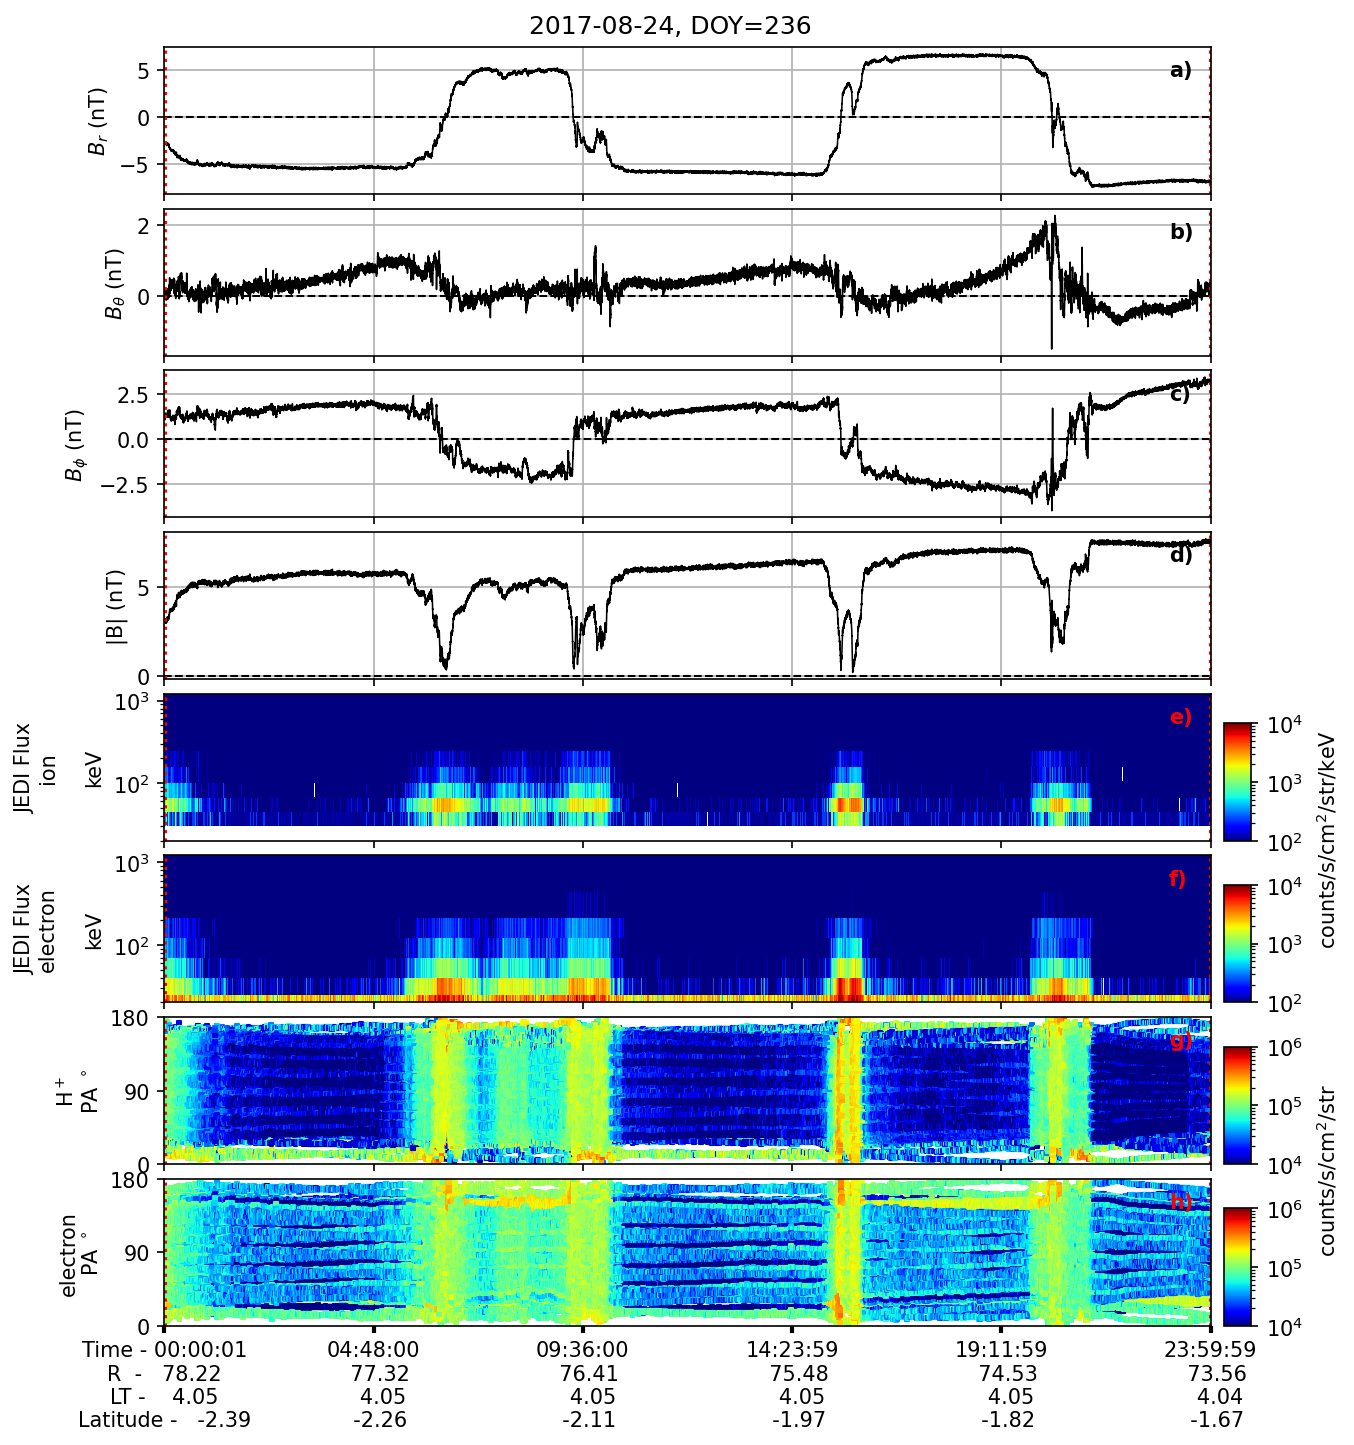

In [6]:
def plot_data(magdata, ion_data=None, electron_data=None, start=None, end=None, outfolder=None, sevent=None, eevent=None):
    """Plot data between start and end."""
    
    # Find the ticks.
    timearray, tickstring = find_ticks_between(start, end)
    
    # Create the figure.
    fig, axs = plt.subplots(4 + 4, 1, 
                            gridspec_kw={'hspace': 0.1, 'right':0.9, 'top':0.9}, 
                            figsize=(9, 11), 
                            dpi=150)
    
    axs[:4] = magdata.plot(vars=['Br', 'Btheta', 'Bphi', 'Bmag'], axs=axs[:4])
    
    if ion_data:
        ion_data.plot_flux_spectra(ax=axs[4])
        ion_data.plot_pitchangle_scatter(ax=axs[6], size=3.)
        # ion_data.plot_pitchangle_spectra(ax=axs[6], vmin=1e6, vmax=1e8, cmap='jet')
    
    if electron_data:
        electron_data.plot_flux_spectra(ax=axs[5])
        electron_data.plot_pitchangle_scatter(ax=axs[7], size=3.)
        # ectron_data.plot_pitchangle_spectra(ax=axs[7], vmin=1e5, vmax=1e7, cmap='jet')
    
    for a in axs:
        a.set_xlim([timearray[0], timearray[-1]])
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring)
        a.label_outer()
        a.axvline(sevent, ls='dotted', color='r') # [0.2, 0.2, 0.2])
        a.axvline(eevent, ls='dotted', color='r')
            
            
    annotations = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)']
    for i, a in enumerate(axs):
        if i < 4:
             a.text(0.96, 0.8, annotations[i], transform=a.transAxes, weight='bold')
        else:
            a.text(0.96, 0.8, annotations[i], transform=a.transAxes, color='r', weight='bold')
        
    axs[4].text(1.1, -0.7, r'counts/s/cm$^2$/str/keV', transform=axs[4].transAxes, rotation=90)
    axs[6].text(1.1, -0.6, r'counts/s/cm$^2$/str', transform=axs[6].transAxes, rotation=90)

    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)
    
    plt.suptitle(dt.datetime.strftime(start, '%Y-%m-%d') + \
                 ', DOY={:s}'.format(dt.datetime.strftime(start, '%j')), y=0.92)
    
    if outfolder:
        fig.savefig(outfolder + dt.datetime.strftime(start, '%Y-%jT%H:%M') + '.png')
        plt.close(fig)
    
    plt.show()
    fig.savefig('out_images/' + dt.datetime.strftime(start, '%Y-%jT%H:%M') + '.png')
    
    # plt.close(fig)
    
plot_data(magdata, ion_data=ion_data, electron_data=electron_data, start=start, end=end, sevent=startevent, eevent=endevent)